SALES DATA


,Product,Region,Quantity,Unit_Price,Unit_Cost,Revenue,Profit
0,Laptop,North,5,1000,750,5000,1250
1,Phone,South,10,500,350,5000,1500
2,Tablet,East,8,300,200,2400,800
3,Laptop,West,3,1000,750,3000,750
4,Phone,North,12,500,350,6000,1800
5,Tablet,South,6,300,200,1800,600
6,Laptop,East,4,1000,750,4000,1000
7,Phone,West,9,500,350,4500,1350
8,Tablet,North,7,300,200,2100,700
9,Laptop,South,2,1000,750,2000,500



BUSINESS KPI SUMMARY
Total Revenue: 35800
Total Profit: 10250
Profit Margin (%): 28.63

REVENUE BY PRODUCT


,Revenue
Product,
Phone,15500
Laptop,14000
Tablet,6300


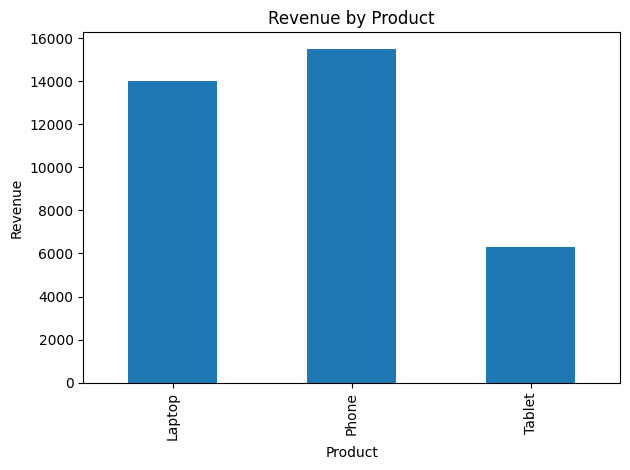

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Sample sales dataset
data = {
    "Product": ["Laptop", "Phone", "Tablet", "Laptop", "Phone",
                "Tablet", "Laptop", "Phone", "Tablet", "Laptop"],
    "Region": ["North", "South", "East", "West", "North",
               "South", "East", "West", "North", "South"],
    "Quantity": [5, 10, 8, 3, 12, 6, 4, 9, 7, 2],
    "Unit_Price": [1000, 500, 300, 1000, 500,
                   300, 1000, 500, 300, 1000],
    "Unit_Cost": [750, 350, 200, 750, 350,
                  200, 750, 350, 200, 750]
}

df = pd.DataFrame(data)

# Calculate revenue and profit
df["Revenue"] = df["Quantity"] * df["Unit_Price"]
df["Profit"] = df["Quantity"] * (
    df["Unit_Price"] - df["Unit_Cost"]
)

print("SALES DATA")
display(df)

print("\nBUSINESS KPI SUMMARY")
print("Total Revenue:", df["Revenue"].sum())
print("Total Profit:", df["Profit"].sum())
print("Profit Margin (%):",
      round(df["Profit"].sum() / df["Revenue"].sum() * 100, 2))

print("\nREVENUE BY PRODUCT")
display(df.groupby("Product")["Revenue"].sum().sort_values(ascending=False))

# Visualize revenue by product
df.groupby("Product")["Revenue"].sum().plot(
    kind="bar", title="Revenue by Product"
)
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [4]:
# BUSINESS ANALYSIS: PRODUCT PERFORMANCE

product_analysis = df.groupby("Product").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum")
)

product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Profit"]
    / product_analysis["Total_Revenue"] * 100
).round(2)

product_analysis = product_analysis.sort_values(
    by="Total_Revenue", ascending=False
)

display(product_analysis)

# Identify the best-performing products
print("Highest Revenue Product:",
      product_analysis["Total_Revenue"].idxmax())

print("Highest Profit Product:",
      product_analysis["Total_Profit"].idxmax())

print("Highest Profit Margin Product:",
      product_analysis["Profit_Margin_%"].idxmax())

,Total_Quantity,Total_Revenue,Total_Profit,Profit_Margin_%
Product,,,,
Phone,31,15500,4650,30.00
Laptop,14,14000,3500,25.00
Tablet,21,6300,2100,33.33


Highest Revenue Product: Phone
Highest Profit Product: Phone
Highest Profit Margin Product: Tablet


,Total_Revenue,Total_Profit,Total_Quantity,Profit_Margin_%
Region,,,,
North,13100,3750,24,28.63
South,8800,2600,18,29.55
West,7500,2100,12,28.00
East,6400,1800,12,28.12


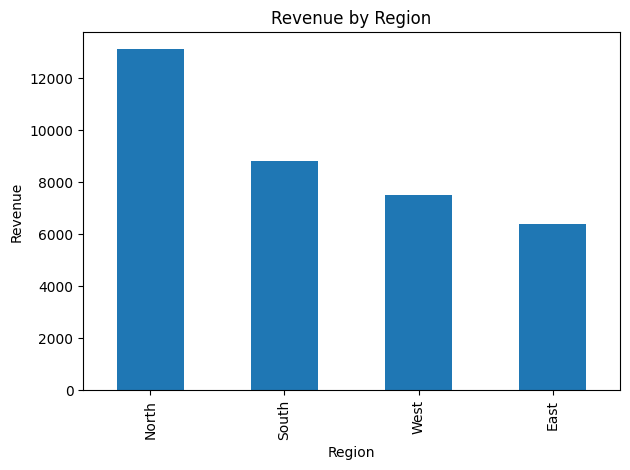

In [5]:
# REGIONAL SALES PERFORMANCE

region_analysis = df.groupby("Region").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Revenue"] * 100
).round(2)

region_analysis = region_analysis.sort_values(
    by="Total_Revenue", ascending=False
)

display(region_analysis)

region_analysis["Total_Revenue"].plot(
    kind="bar",
    title="Revenue by Region",
    ylabel="Revenue",
    xlabel="Region"
)

plt.tight_layout()
plt.show()

,Total_Revenue,Total_Profit,Total_Quantity,Profit_Margin_%
Region,,,,
North,13100,3750,24,28.63
South,8800,2600,18,29.55
West,7500,2100,12,28.00
East,6400,1800,12,28.12


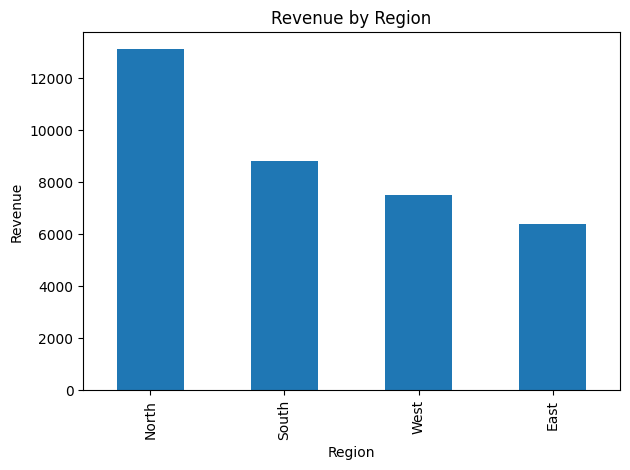

In [6]:
# REGIONAL SALES PERFORMANCE

region_analysis = df.groupby("Region").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Revenue"] * 100
).round(2)

region_analysis = region_analysis.sort_values(
    by="Total_Revenue", ascending=False
)

display(region_analysis)

region_analysis["Total_Revenue"].plot(
    kind="bar",
    title="Revenue by Region",
    ylabel="Revenue",
    xlabel="Region"
)

plt.tight_layout()
plt.show()

In [8]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("sales", conn, index=False, if_exists="replace")

query = """
SELECT
    Region,
    SUM(Revenue) AS Total_Revenue,
    SUM(Profit) AS Total_Profit,
    ROUND(100.0 * SUM(Profit) / SUM(Revenue), 2) AS Profit_Margin
FROM sales
GROUP BY Region
ORDER BY Total_Revenue DESC;
"""

sql_results = pd.read_sql_query(query, conn)
display(sql_results)

,Region,Total_Revenue,Total_Profit,Profit_Margin
0,North,13100,3750,28.63
1,South,8800,2600,29.55
2,West,7500,2100,28.00
3,East,6400,1800,28.13
